In [1]:
using DataDrivenDiffEq
using ModelingToolkit
using OrdinaryDiffEq
using DataDrivenSparse
using LinearAlgebra

# Create a test problem
function lorenz(u, p, t)
    x, y, z = u

    ẋ = 10.0 * (y - x)
    ẏ = x * (28.0 - z) - y
    ż = x * y - (8 / 3) * z
    return [ẋ, ẏ, ż]
end

u0 = [1.0; 0.0; 0.0]
tspan = (0.0, 10.0)
dt = 0.001
prob = ODEProblem(lorenz, u0, tspan)
sol = solve(prob, Tsit5(), saveat = dt)

## Start the automatic discovery

X = Array(sol) 
t = sol.t


# 2. Create the problem using matrices instead of the 'sol' object
# This skips the 'is_successful' check entirely
ddprob = ContinuousDataDrivenProblem(X, t)

# 3. Proceed with discovery
@variables t x(t) y(t) z(t)
u_vars = [x; y; z]
basis = Basis(polynomial_basis(u_vars, 2), u_vars, iv = t)
opt = STLSQ(0.5)

# Try solving without the 'options' argument first to keep it simple
ddsol = solve(ddprob, basis, opt)


"DataDrivenSolution{Float64}"

In [2]:
println(get_basis(ddsol), get_parameter_values(ddsol.basis))

Model ##Basis#282 with 3 equations
States : x(t) y(t) z(t)
Parameters : 7
Independent variable: t
Equations
Differential(t)(x(t)) = p₁*x(t) + p₂*y(t)
Differential(t)(y(t)) = p₃*x(t) + p₄*y(t) + p₅*x(t)*z(t)
Differential(t)(z(t)) = p₇*z(t) + p₆*x(t)*y(t)
[-9.9952568238, 9.9995932219, 27.683592383, -0.8449891312, -0.9938972891, 0.9995675623, -2.6646274877]


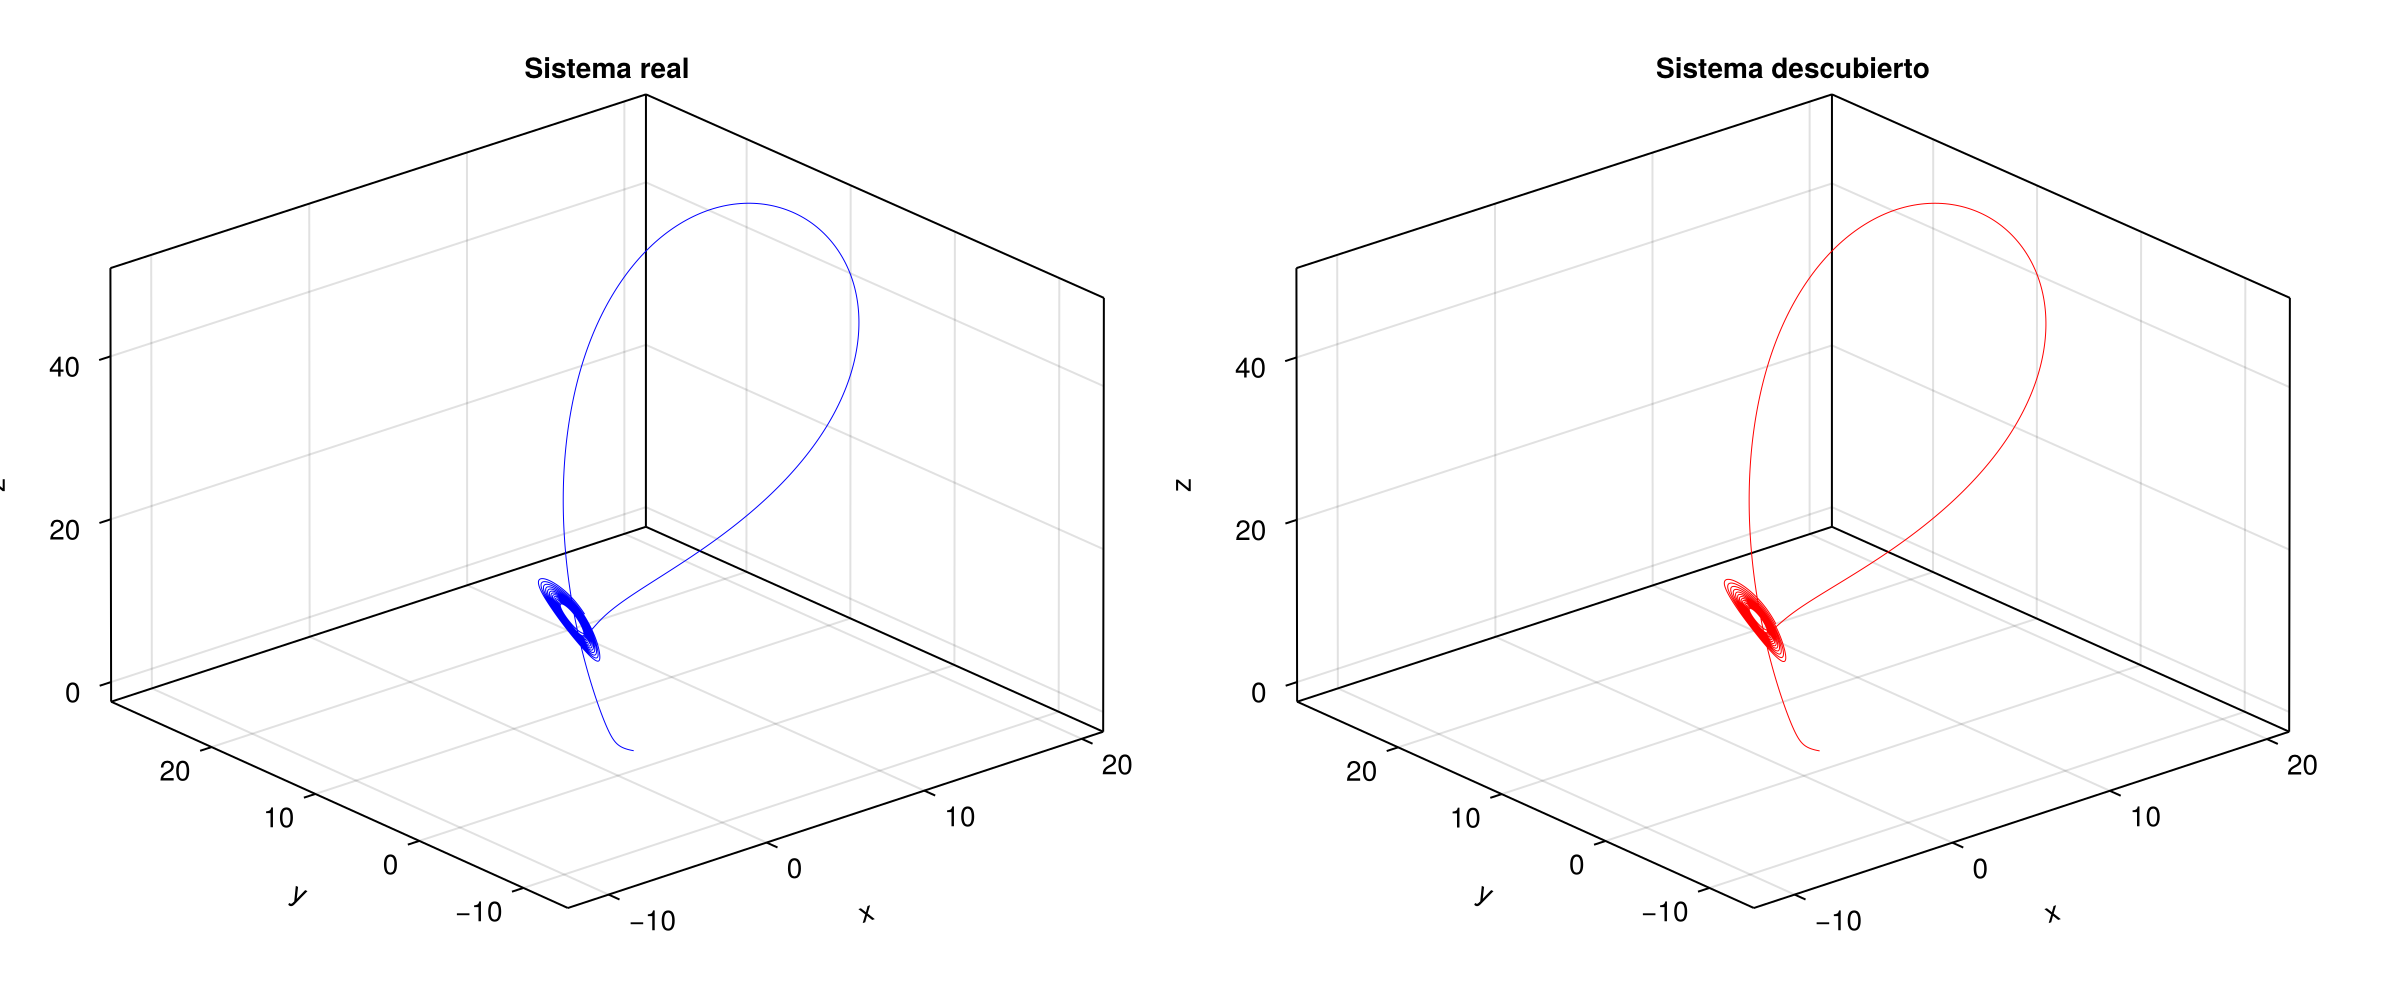

CairoMakie.Screen{IMAGE}


In [5]:
using CairoMakie

# ── 1. Extraer el sistema descubierto ─────────────────────────────────────
discovered_basis = get_basis(ddsol)
ps = [v for (_, v) in get_parameter_map(discovered_basis)]

function discovered_sys!(du, u, p, t)
    du .= discovered_basis(u, p, t)
end

# ── 2. Integrar el sistema descubierto ────────────────────────────────────
prob_disc = ODEProblem(discovered_sys!, u0, tspan, ps)
sol_disc  = solve(prob_disc, Tsit5(), saveat=dt)

# ── 3. Plot 3D con CairoMakie ─────────────────────────────────────────────
fig = Figure(size = (1200, 500))

ax1 = Axis3(fig[1, 1], title = "Sistema real",
            xlabel = "x", ylabel = "y", zlabel = "z")
lines!(ax1, sol[1, :], sol[2, :], sol[3, :],
       color = :blue, linewidth = 0.5)

ax2 = Axis3(fig[1, 2], title = "Sistema descubierto",
            xlabel = "x", ylabel = "y", zlabel = "z")
lines!(ax2, sol_disc[1, :], sol_disc[2, :], sol_disc[3, :],
       color = :red, linewidth = 0.5)

display(fig)

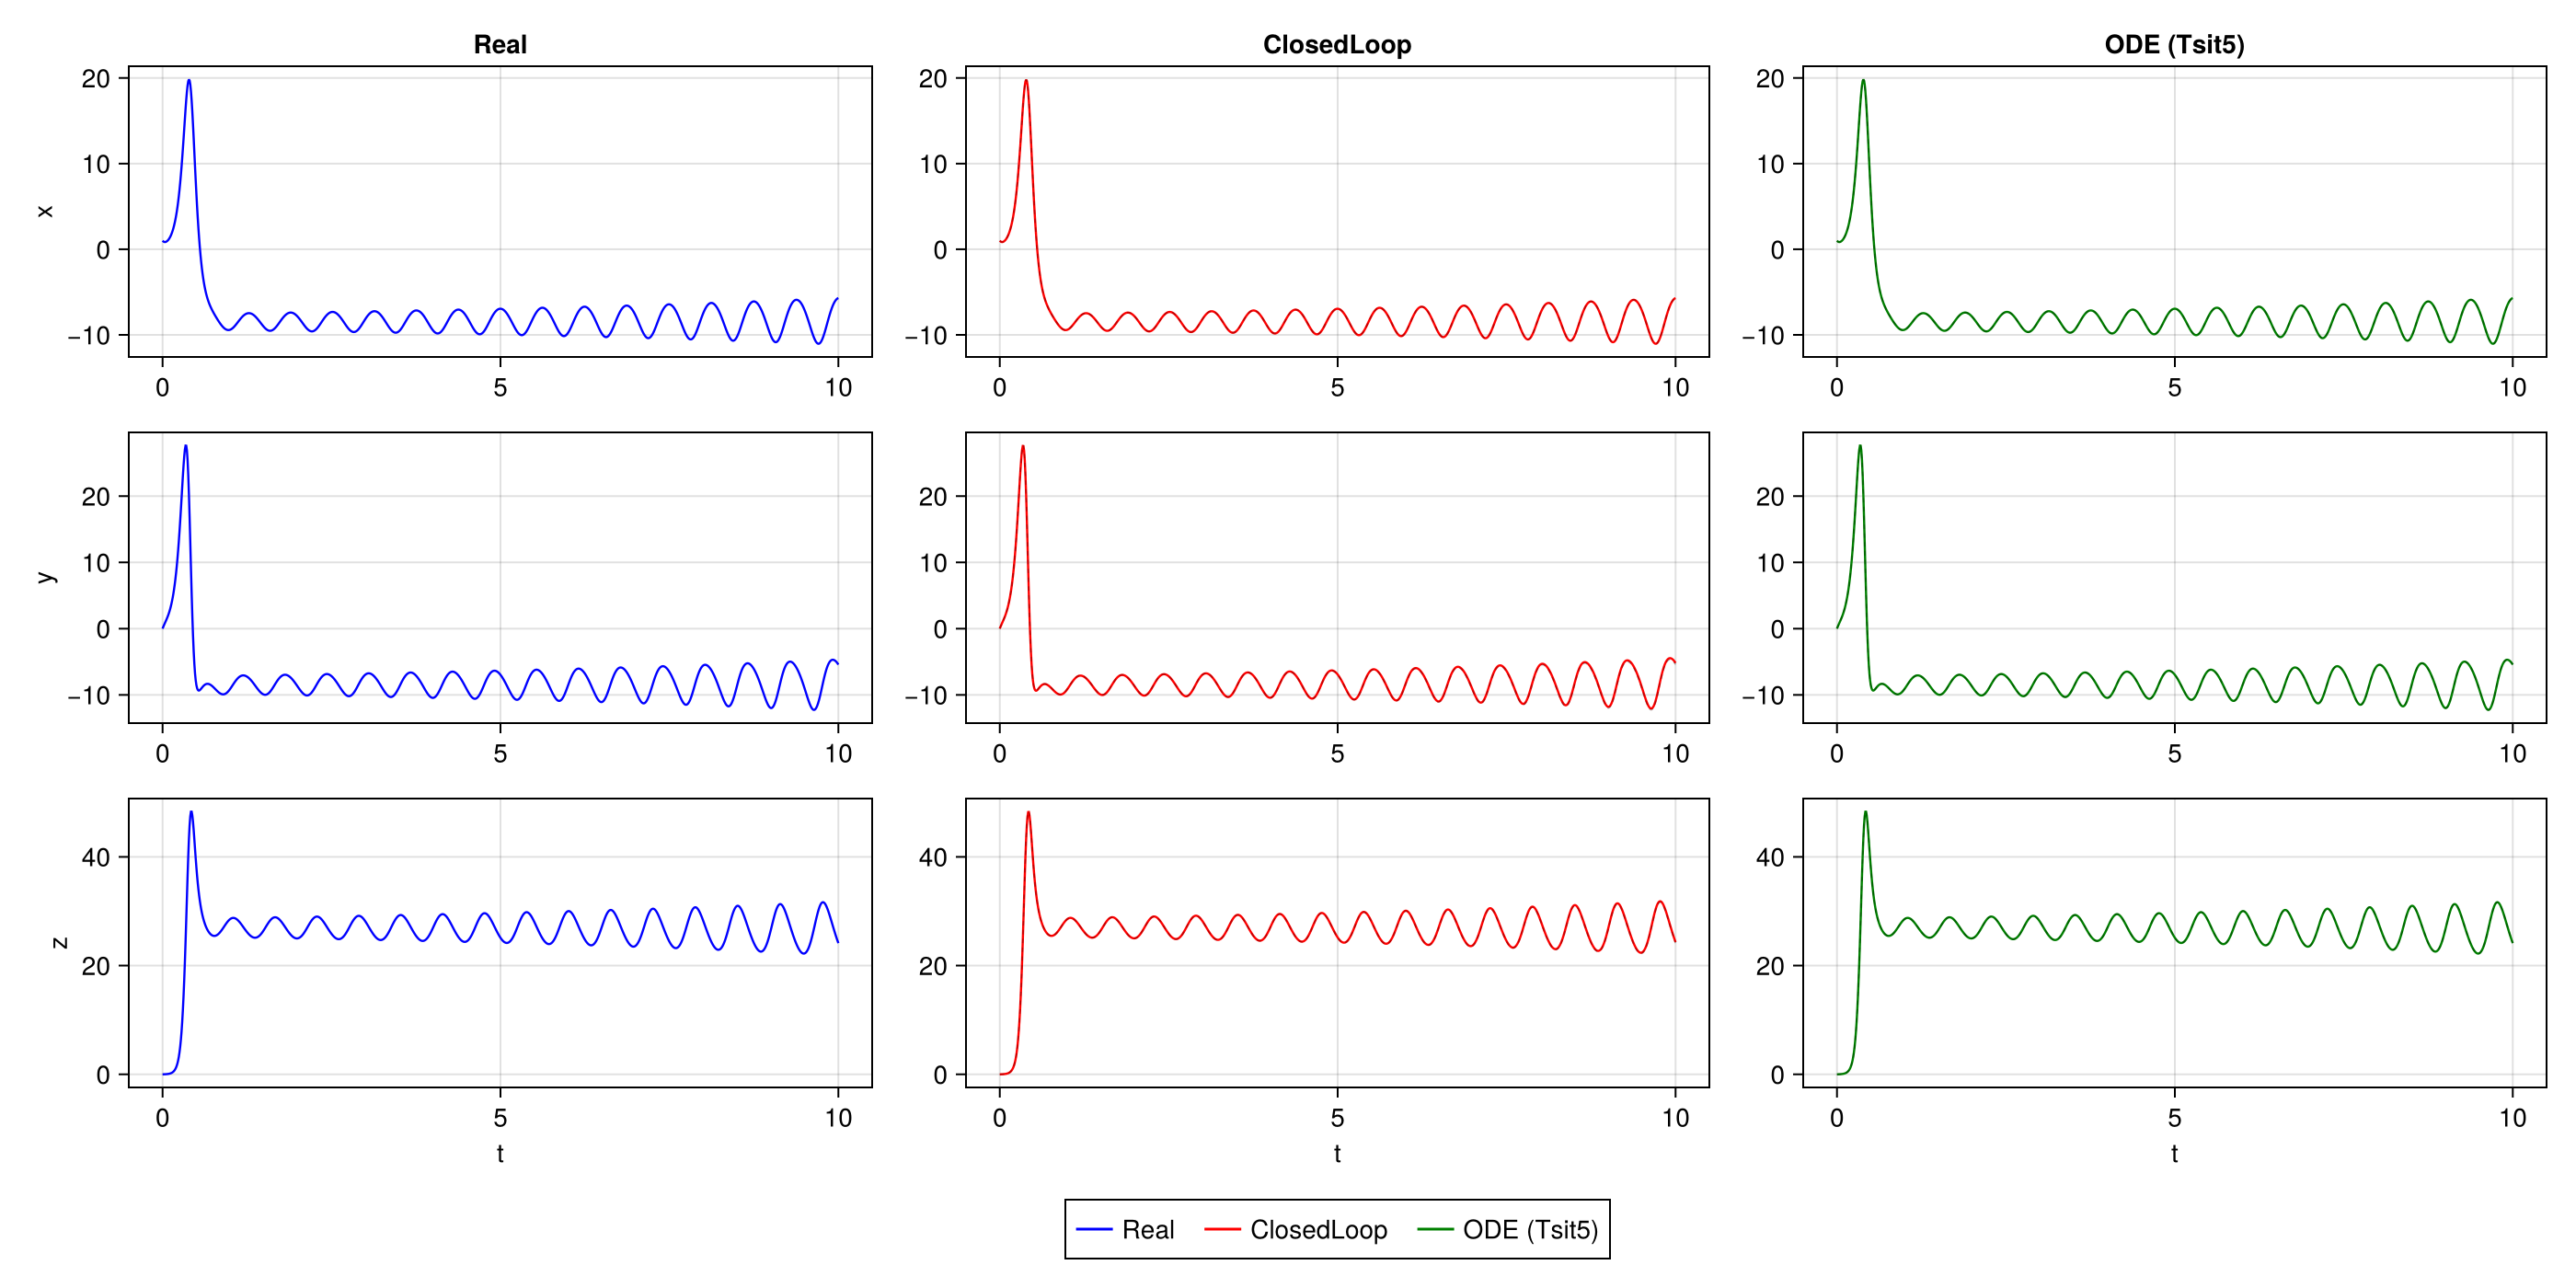

CairoMakie.Screen{IMAGE}


In [ ]:
using OrdinaryDiffEq, CairoMakie

function constant_interpolation(U, t, t_val)
    k = searchsortedlast(t, t_val)
    k = clamp(k, 1, length(t))
    return U[:, k]
end

# ── 1. Lorenz ──────────────────────────────────────────────────────────────
function lorenz(u, p, t)
    x, y, z = u
    return [10.0*(y-x), x*(28.0-z)-y, x*y-(8/3)*z]
end

u0    = [1.0, 0.0, 0.0]
tspan = (0.0, 10.0)
dt    = 0.01
sol   = solve(ODEProblem(lorenz, u0, tspan), Tsit5(), saveat=dt)
X     = Array(sol)
t     = sol.t
U     = zeros(1, length(t))
p_opt = Float64[]
lorenz_basis(u, p, t, u_ctrl) = lorenz(u, p, t)

# ── 2. Integradores ────────────────────────────────────────────────────────
function integrate_closedloop(f, p_opt, X, U, t)
    n_states, n_t = size(X)
    X_sim         = zeros(Float64, n_states, n_t)
    X_sim[:, 1]  .= X[:, 1]
    @views for k in 2:n_t
        dt_k    = t[k] - t[k-1]
        u_prev  = constant_interpolation(U, t, t[k-1])
        u_curr  = constant_interpolation(U, t, t[k])
        dX_prev = f(X[:, k-1], p_opt, t[k-1], u_prev)
        dX_curr = f(X[:, k],   p_opt, t[k],   u_curr)
        X_sim[:, k] .= X_sim[:, k-1] .+ 0.5 .* dt_k .* (dX_prev .+ dX_curr)
    end
    return X_sim
end

function integrate_ode(f, p_opt, X, U, t)
    prob = ODEProblem(
        (du, u, p, t_val) -> du .= f(u, p, t_val, constant_interpolation(U, t, t_val)),
        Vector(X[:, 1]),
        (t[1], t[end]),
        p_opt
    )
    return Array(solve(prob, Tsit5(), saveat=t))
end

# ── 3. Integrar ────────────────────────────────────────────────────────────
X_cl  = integrate_closedloop(lorenz_basis, p_opt, X, U, t)
X_ode = integrate_ode(lorenz_basis, p_opt, X, U, t)

# ── 4. Plot: series temporales ─────────────────────────────────────────────
state_labels = ["x", "y", "z"]
colors       = [:blue, :red, :green]
labels       = ["Real", "ClosedLoop", "ODE (Tsit5)"]
data         = [X, X_cl, X_ode]

fig  = Figure(size = (1400, 700))
axes = Matrix{Axis}(undef, 3, 3)   # ← guardar referencias a los Axis

for (row, state_name) in enumerate(state_labels)
    for (col, (Xd, label, color)) in enumerate(zip(data, labels, colors))
        ax = Axis(fig[row, col],
            xlabel     = row == 3 ? "t" : "",
            ylabel     = col == 1 ? state_name : "",
            title      = row == 1 ? label : "",
            titlesize  = 14,
            ylabelsize = 14,
        )
        axes[row, col] = ax   # ← guardar el Axis

        lines!(ax, t, Xd[row, :], color = color, linewidth = 1.2)

        if col > 1
            lines!(ax, t, X[row, :],
                color     = (:black, 0.25),
                linewidth = 0.8,
                linestyle = :dash
            )
        end
    end
    linkyaxes!(axes[row, :]...)   # ← ahora sí recibe Axis, no GridPosition
end

Legend(fig[4, 1:3],
    [LineElement(color = c, linewidth = 1.5) for c in colors],
    labels,
    orientation = :horizontal,
    tellwidth   = false
)

display(fig)